# The inputs across many fires

One row per fire, fires from different states. Columns: the fire's footprint, forest share, slope, greenness anomaly, distance to the nearest road, and the **target** (cells that burned within 48 hours).
Every picture is a 19.2 km square, 100 m per pixel, the exact arrays the image models are trained on (`data/maps_48h.npz`). This shows what the models have to cope with: dense forest, patchy cropland, steep and flat ground, wet and dry years.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, textwrap, warnings
warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.dpi': 105, 'font.size': 8})
z = np.load('../data/maps_48h.npz'); names = list(z['names']); N = len(z['case'])
info = pd.DataFrame({k: z[k] for k in ('case', 'split', 'state', 'year')}); info['burned'] = z['y'].reshape(N, -1).sum(1); info['asked'] = z['cand'].reshape(N, -1).sum(1)
print(N, 'fires,', info.state.nunique(), 'states; years', sorted(info.year.unique()))
print(info.groupby('state').size().sort_values(ascending=False).head(12).to_string())

834 fires, 24 states; years [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
state
Andhra Pradesh    103
Madhya Pradesh     96
Mahārāshtra        87
Telangāna          80
Chhattīsgarh       69
Uttarākhand        51
Odisha             44
Rājasthān          39
Bihār              33
Uttar Pradesh      33
Karnātaka          33
Jhārkhand          30


In [2]:
rng = np.random.default_rng(3); pick = []
for st in info.state.value_counts().index[:7]:
    sub = info[(info.state == st) & (info.burned > 150)]
    if len(sub): pick.append(int(rng.choice(sub.index)))
cols = [('seed', 'fire footprint', 'Reds'), ('forest_share', 'forest-land share', 'Greens'), ('slope', 'slope (deg)', 'YlOrBr'), ('ndvi_anom', 'greenness anomaly', 'BrBG'), ('road_dist', 'distance to road (cells)', 'viridis')]
fig, axs = plt.subplots(len(pick), len(cols) + 1, figsize=(15, 2.5 * len(pick)))
for r, i in enumerate(pick):
    X = z['X'][i].astype(np.float32)
    for k, (nm, ttl, cm) in enumerate(cols):
        v = X[names.index(nm)]; ax = axs[r, k]; ax.imshow(v, cmap=cm, interpolation='nearest'); ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(ttl)
    ax = axs[r, -1]; t = z['y'][i].astype(float); m = z['cand'][i] > 0
    ax.imshow(np.where(m, 0.15, np.nan), cmap='Greys', vmin=0, vmax=1); ax.imshow(np.where(t > 0, 1.0, np.nan), cmap='Reds', vmin=0, vmax=1.3); ax.set_xticks([]); ax.set_yticks([])
    if r == 0: ax.set_title('TARGET: burned within 48 h (red) in the cells asked about (grey)')
    axs[r, 0].set_ylabel(f"{info.state[i]}\n{int(info.year[i])}\n{int(info.burned[i])} burned", fontsize=8)
plt.tight_layout(); plt.show()

## How much of each square is actually asked about, and how little burns

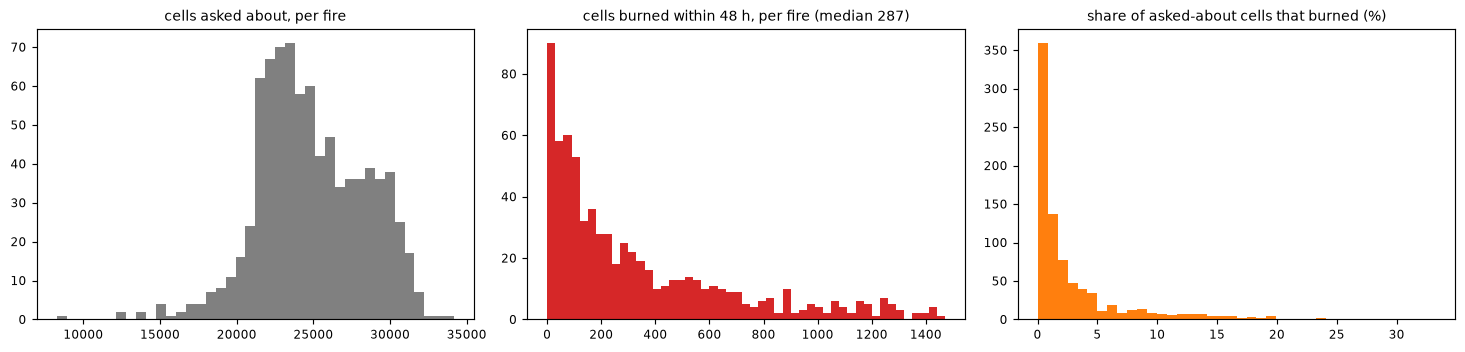

median burned share: 1.17 % of the cells asked about. Picking cells at random would hit that share; the models rank cells so that far more of the top ones are burned.


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.4))
ax[0].hist(info.asked, bins=40, color='grey'); ax[0].set_title('cells asked about, per fire')
ax[1].hist(info.burned, bins=np.arange(0, 1500, 30), color='tab:red'); ax[1].set_title('cells burned within 48 h, per fire (median %d)' % info.burned.median())
ax[2].hist(100 * info.burned / info.asked, bins=40, color='tab:orange'); ax[2].set_title('share of asked-about cells that burned (%)')
plt.tight_layout(); plt.show()
print('median burned share: %.2f %% of the cells asked about. Picking cells at random would hit that share; the models rank cells so that far more of the top ones are burned.' % np.median(100 * info.burned / info.asked))

## Fires by state, year and split

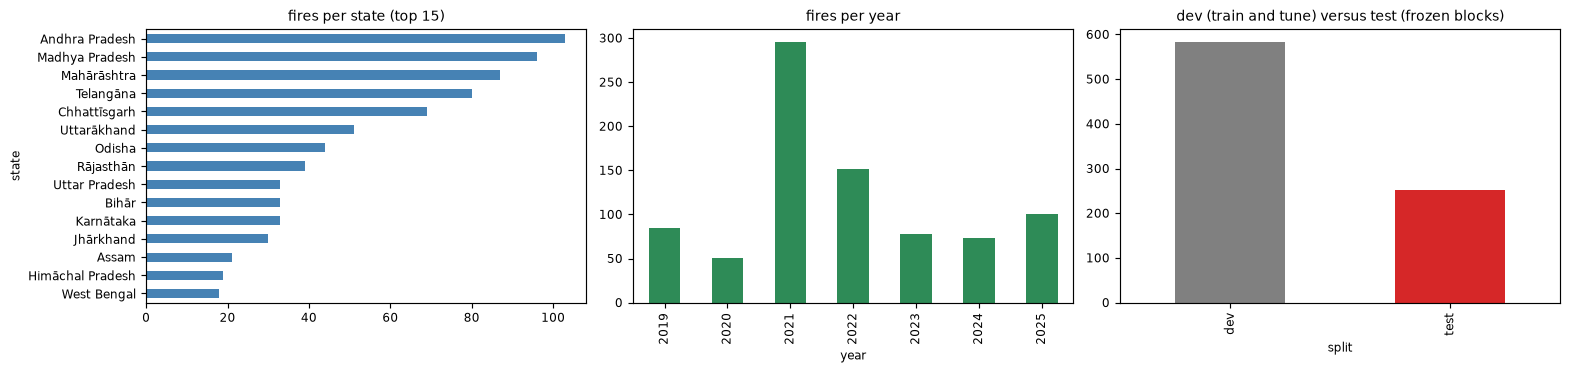

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
info.groupby('state').size().sort_values().tail(15).plot.barh(ax=ax[0], color='steelblue'); ax[0].set_title('fires per state (top 15)')
info.groupby('year').size().plot.bar(ax=ax[1], color='seagreen'); ax[1].set_title('fires per year')
info.split.value_counts().plot.bar(ax=ax[2], color=['grey', 'tab:red']); ax[2].set_title('dev (train and tune) versus test (frozen blocks)')
plt.tight_layout(); plt.show()